# Primer zadatka klasifikacije teksta

U fajlu “Disneyland_reviews_for_class.csv” su dati podaci o komentarima posetilaca Disneyland
parkova. Fajl sadrži sledeće kolone (varijable):

* Review_ID - jedinstveni identifikator komentara
* Rating - ocena koju je posetilac dao parku
* Year_Month - godina i mesec posete na koju se komentar odnosi
* Reviewer_Location - država iz koje je autor komentara
* Review_Test - tekst komentara
* Branch - ogranak Disneyland parka koji je predmet komentara

Koristeći opisane podatke iz navedenog fajla, potrebno je uraditi sledeće:
*  Polazeći od kolone Rating napraviti novu sentiment varijablu sa tri moguće vrednosti (negativan, neutralan, pozitivan) primenjujući sledeće mapiranje:
    * rating 1 i 2 se mapiraju u “negativan” sentiment,
    * rating 3 se mapira u “neutralan” sentiment,
    * rating 4 i 5 se mapiraju u “pozitivan” sentiment

    Varijabla sentiment bi trebalo da posluži kao izlazna varijabla za klasifikaciju u ovom zadatku.


* Transformisati kolonu Review_Text u numerički oblik primenom Bag of Words modela i
konkretno, TF metrike za procenu značajnosti reči. Takođe, proceniti da li bi još neku od
varijabli iz polaznog dataset-a trebalo primeniti za kreiranje modela i ako se opredelite
da neku / neke varijable uključite, obrazložite ukratko odluku.


* Kreirati prvi klasifikacioni model primenom algoritma Support Vector Machines (SVM), sa
linearnim kernelom i podrazumevanim vrednostima hiperparametara.


* Napraviti predikcije primenom kreiranog modela i izračunati standardne evaluacione
metrike (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj. na
nivou svih klasa. Interpretirati dobijene vrednosti metrika u kontekstu zadatka.


* Kreirati drugi klasifikacioni model kroz postupak podešavanja hiperparametara. U
komentaru navesti koje biste hiperparametre podešavali i na koji način tj. koristeći koje
opsege / liste vrednosti ako ne biste bili vremenski ograničeni. Zatim, izabrati dva
hiperparametra, jedan za transformaciju teksta, drugi za klasifikator, odnosno oba za
klasifikator ako hiperparametri nisu primenljivi za transformaciju teksta, i izvršite
podešavanje njihovih vrednosti kroz postupak (5-fold) kros-validacije.


* Izvršiti predikcije primenom podešenog modela i izračunati standardne evaluacione
metrike (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj. na
nivou svih klasa.


* Uporediti i prokomentarisati rezultate dobijene osnovnim i podešenim modelima.

In [1]:
from unittest.mock import inplace

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

from sentence_transformers import SentenceTransformer

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

In [2]:
RAND_STATE = 1
SPACY_MODEL = 'en_core_web_sm'

### UCITAVANJE I PRIPREMA PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'Disneyland_reviews_for_class.csv')
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,532711443,5,2017-9,United States,We've been coming since our grown kids were yo...,Disneyland_California
1,230885912,5,2014-5,United States,"Yes, it's crowded and the lines are long and e...",Disneyland_California
2,130119156,4,2012-5,Ireland,We're just back from Disneyland Paris and we h...,Disneyland_Paris
3,472057505,4,2017-4,Philippines,We were surprised that we didn't have to wait ...,Disneyland_HongKong
4,385661044,5,2015-7,United States,I can't say enough about this place. When I ev...,Disneyland_California


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Review_ID          3000 non-null   int64
 1   Rating             3000 non-null   int64
 2   Year_Month         3000 non-null   str  
 3   Reviewer_Location  3000 non-null   str  
 4   Review_Text        3000 non-null   str  
 5   Branch             3000 non-null   str  
dtypes: int64(2), str(4)
memory usage: 140.8 KB


KREIRANJE IZLAZNE VARIJABLE

In [5]:
def get_sentiment(rating):
    if rating == 3: return 'neutralan'
    return 'pozitivan' if rating > 3 else 'negativan'

data['sentiment'] = data.Rating.apply(get_sentiment)
data[['Rating','sentiment']].sample(10)

,Rating,sentiment
1494,5,pozitivan
1947,4,pozitivan
1787,5,pozitivan
1505,4,pozitivan
2818,4,pozitivan
1441,5,pozitivan
2854,5,pozitivan
441,5,pozitivan
485,5,pozitivan
1420,2,negativan


In [6]:
data.sentiment.value_counts(normalize=True)

sentiment
pozitivan    0.796333
neutralan    0.120667
negativan    0.083000
Name: proportion, dtype: float64

In [7]:
# dosta neizbalansirane klase

### IZBOR PREDIKTORA

In [8]:
# nema NA vrednosti, ali cu od varijable 'Year_Month' napraviti varijablu 'month' izvlacenjem meseca

data['month'] = data.Year_Month.apply(lambda x: int(x.split('-')[1]))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,sentiment,month
0,532711443,5,2017-9,United States,We've been coming since our grown kids were yo...,Disneyland_California,pozitivan,9
1,230885912,5,2014-5,United States,"Yes, it's crowded and the lines are long and e...",Disneyland_California,pozitivan,5
2,130119156,4,2012-5,Ireland,We're just back from Disneyland Paris and we h...,Disneyland_Paris,pozitivan,5
3,472057505,4,2017-4,Philippines,We were surprised that we didn't have to wait ...,Disneyland_HongKong,pozitivan,4
4,385661044,5,2015-7,United States,I can't say enough about this place. When I ev...,Disneyland_California,pozitivan,7


In [9]:
data.month.value_counts()

month
8     289
12    287
7     286
10    277
5     263
4     263
6     259
9     247
3     239
11    213
1     190
2     187
Name: count, dtype: int64

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Review_ID          3000 non-null   int64
 1   Rating             3000 non-null   int64
 2   Year_Month         3000 non-null   str  
 3   Reviewer_Location  3000 non-null   str  
 4   Review_Text        3000 non-null   str  
 5   Branch             3000 non-null   str  
 6   sentiment          3000 non-null   str  
 7   month              3000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 187.6 KB


Varijabla `Review_ID` oznacava redni broj, tako da nije znacajna za klasifikaciju.

Varijabla `Rating` je koriscena za kreiranje izlazne varijable - nece biti prediktor.

Ocenicemo znacajnost ostalih varijabli.

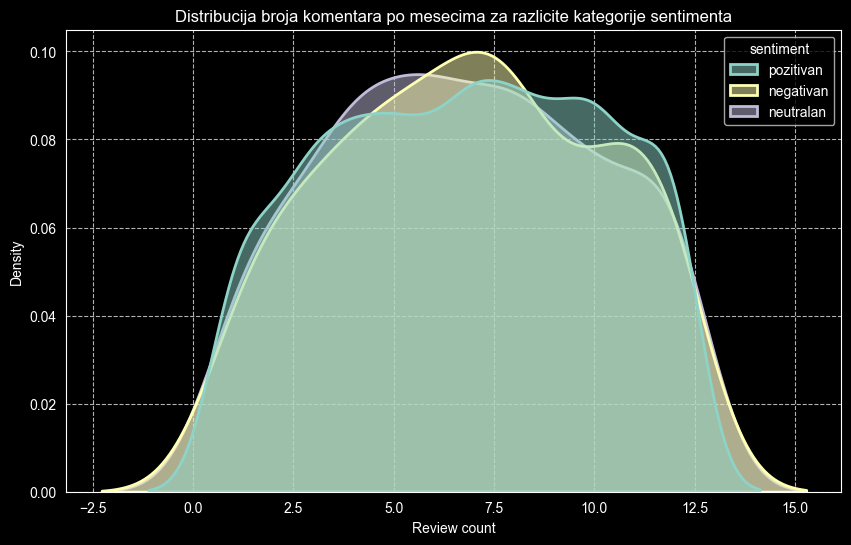

In [11]:
plt.figure(figsize=(10, 6))

sb.kdeplot(data=data,
           x='month',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja komentara po mesecima za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Varijabla `month` ima slicne raspodele za sve tri klase sentimenta - nece biti prediktor.

In [12]:
data.Reviewer_Location.nunique()

86

In [13]:
data.Reviewer_Location.value_counts()

Reviewer_Location
United States     1036
United Kingdom     701
Australia          323
Canada             176
India               92
                  ... 
Guernsey             1
Albania              1
Austria              1
Mauritius            1
Estonia              1
Name: count, Length: 86, dtype: int64

Varijabla `Reviewer_Location` ima 86 jedinstvenih vrednosti, sto je mnogo da bi se ukljucila kroz one-hot-encoding.


Posto bi lokacija mogla da bude vazan faktor jer je na razlicitim lokacijama drugaciji kvalitet prostora i usluge, prve tri najcesce lokacije (sa najvise redova) bi eventualno mogde da se zadrze pod svojim nazivom, a da se ostale grupisu u kategoriju 'other', kako bi se zadrzali svi redovi u datasetu.


Ipak, najjednostavije resenje je da je samo ne ukljucimo u model.
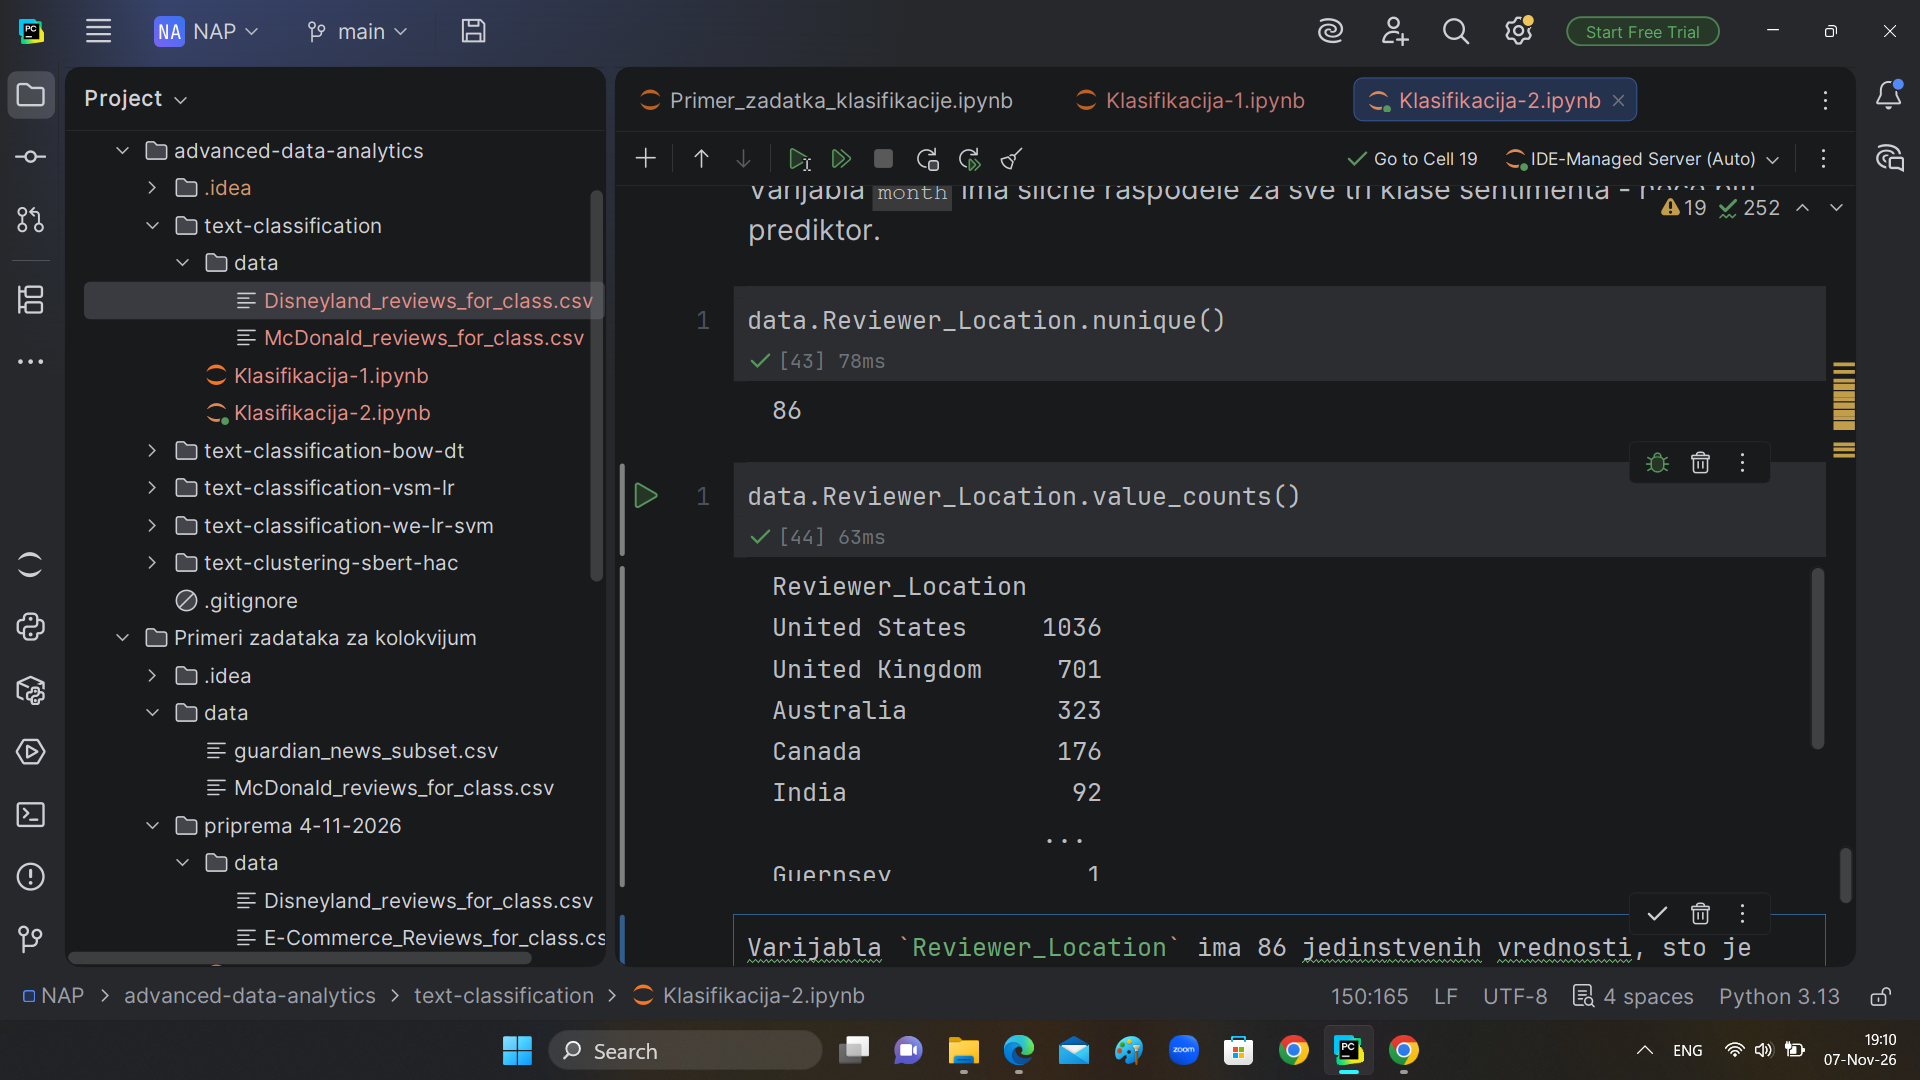

In [14]:
data.Branch.nunique()

3

In [15]:
data.Branch.value_counts()

Branch
Disneyland_California    1356
Disneyland_Paris          971
Disneyland_HongKong       673
Name: count, dtype: int64

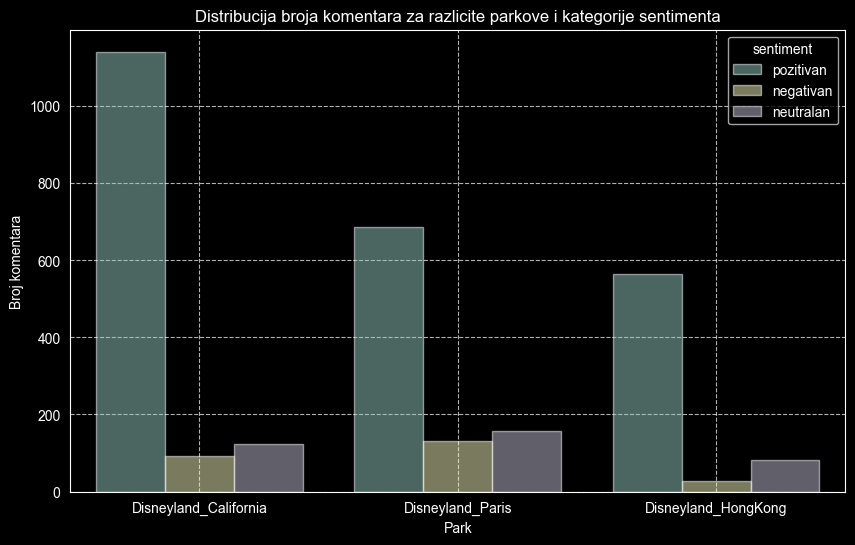

In [16]:
plt.figure(figsize=(10, 6))

sb.countplot(data=data,
           x='Branch',
           hue='sentiment',
           fill=True,
           alpha=0.5)

plt.title('Distribucija broja komentara za razlicite parkove i kategorije sentimenta')
plt.xlabel('Park')
plt.ylabel('Broj komentara')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Varijabla `Branch` ce postati prediktor posto je njene 3 jedinstvene vrednosti zgodno transformisati kroz one-hot-encoding, dok na grafiku vidimo da se proporcije klasa razlikuju u zavisnosti od vrednosti varijable.

In [17]:
one_hot_encoder = OneHotEncoder(drop='first', sparse_output=False)

Zakljucak je da ce prediktori biti varijable `Review_Text` i `Branch`.

### Transformacija teksta primenom Bag of Words modela

In [18]:
spacy_model = spacy.load(SPACY_MODEL, exclude = ['parser','ner'])

In [19]:
def spacy_tokenizer(txt):
    tokens = spacy_model(txt)
    tokens = [token for token in tokens if
              (not token.is_space) and
              (not token.is_punct) and
              (not token.like_url) and
              (not token.like_num)]
    tokens = [token for token in tokens if
              (not token.is_stop) or token.lemma_.lower() == 'not']
    words = [token.lemma_.lower() for token in tokens]
    return words

In [20]:
tf_vectorizer = CountVectorizer(
    tokenizer=spacy_tokenizer,
    token_pattern=None,
    ngram_range=(1,2),
    min_df=0.01,
    max_df=0.95
)

In [21]:
transformer = ColumnTransformer([
    ('one_hot_encoder', one_hot_encoder, ['Branch']),
    ('vectorizer', tf_vectorizer, 'Review_Text')
])

### Kreiranje klasifikatora

In [22]:
classifier = SVC(kernel='linear', random_state=RAND_STATE)

### KREIRANJE I TRENIRANJE PIPELINE-A

In [23]:
X = data[['Review_Text', 'Branch']]
y = data.sentiment

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y_encodings,
                                                    test_size=0.2,
                                                    random_state=RAND_STATE,
                                                    stratify=y_encodings)

In [24]:
pipe = Pipeline([
    ('transformer', transformer),
    ('classifier', classifier)
])

pipe.fit(X_train, y_train)

,steps,"[('transformer', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('one_hot_encoder', ...), ('vectorizer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready f

### EVALUACIJA MODELA

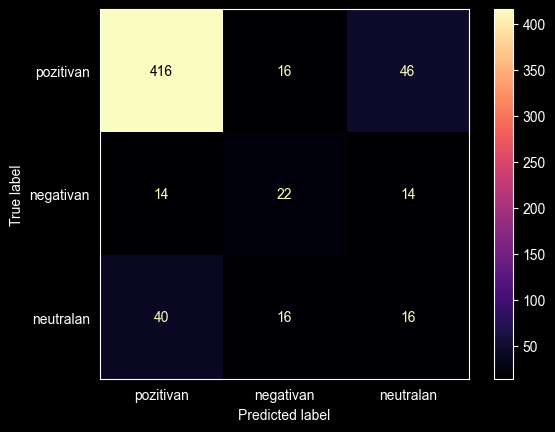

In [25]:
disp = ConfusionMatrixDisplay.from_estimator(pipe,
                                             X_test,
                                             y_test,
                                             display_labels=y_levels,
                                             cmap='magma')
plt.grid(False)

In [26]:
pred_1 = pipe.predict(X_test)
print(classification_report(y_test, pred_1, target_names=y_levels))

              precision    recall  f1-score   support

   pozitivan       0.89      0.87      0.88       478
   negativan       0.41      0.44      0.42        50
   neutralan       0.21      0.22      0.22        72

    accuracy                           0.76       600
   macro avg       0.50      0.51      0.51       600
weighted avg       0.76      0.76      0.76       600



In [27]:
print(balanced_accuracy_score(y_test, pred_1))

0.5108383697505037


### Interpretacija rezultata

Rezultati pokazuju zastupljenost klasa u datom skupu podataka.

Klasa `pozitivan` je najvise zastupljena => pokazuje najbolje rezultate.

Klasa `neutralan` je najmanje zastupljena => pokazuje najslabije rezultate.

Klasa pozitivan:
* precision (preciznost) 0.41 => od svih komentara za koje je predvidjeno da su pozitivnog sentimenta (416+14+40), 41% je stvarno pozitivno
* recall (odziv) 0.87 => od svih komentara koji su stvarno pozitivnog sentimenta (416+16+46), 87% je klasifikovano kao pozitivno
* F1 skor 0.88 => generalno vrlo dobra i balansirana uspesnost modela u prepoznavanju pozitivnog sentimenta

Klasa negativan:
* precision (preciznost) 0.21 => od svih komentara za koje je predvidjeno da su negativnog sentimenta (16+22+16), 21% je stvarno negativno
* recall (odziv) 0.44 => od svih komentara koji su stvarno negativnog sentimenta (14+22+14), 44% je klasifikovano kao negativno
* F1 skor 0.42 => generalno vrlo slaba i nebalansirana uspesnost modela u prepoznavanju negativnog sentimenta

Klasa neutralan:
* precision (preciznost) 0.89 => od svih komentara za koje je predvidjeno da su neutralnog sentimenta (46+14+16), 89% je stvarno neutralno
* recall (odziv) 0.22 => od svih komentara koji su stvarno neutralnog sentimenta (40+16+16), 22% je klasifikovano kao neutralno
* F1 skor 0.22 => vrlo slaba i nebalansirana uspesnost modela u prepoznavanju neutralnog sentimenta

Na nivou svih klasa:
* makro prosek (macro avg) F1 metrike od 0.51 => slaba sposobnost modela da razlikuje sentiment komentara korisnika
* otezani prosek (weighted avg) F1 metrike od 0.76 => relativno dobra sposobnost modela da prepozna dominantan sentiment, posebno pozitivan sentiment

### PODESAVANJE (FINETUNING) HIPERPARAMETARA

Za klasifikator, a u ovom zadatku klasu **`LogisticRegresion`**, posebno se istice hiperparametar **`C`**, koji odredjuje intenzitet regularizacije modela.
* manja vrednost C => jaca regularizacija, povecane sanse za underfitting
* veca vrednost C => slabija regularizacija, povecane sanse za overfitting

Standardne vrednosti hiperparametra C su `0.001, 0.01, 0.1, 1.0, 10, 100`


Hiperparametri koji se najcesce podesavaju pri radu sa TF vektorima, tj. klasom **`CountVectorizer`**, su:
* **`min_df`** - min broj dokumenata u kojima je potrebno da se ngram pojavi  da bi bio ukljucen u skup atributa; `[0.001, 0.01, 0.05]`
* **`max_df`** - max broj dokumenata u kojima se ngram moze naci da bi bio ukljucen u skup atributa; `[0.8, 0.9, 0.95]`
* **`ngram_range`** - ngrami koji ce biti razmotreni za kreiranje skupa atributa; `[(1,1), (1,2), (2,2)]`
* **`max_features`** - max broj atributa koji ce biti selektovani, nakon sortiranja po ucestalosti (frekvenciji) pojavljivanja (_term frequency_); `[1000, 3000, 5000, 10000, 20000, None]`

Za transformaciju ce biti iskoriscen hiperparametar min_df, a za klasifikator C.

In [28]:
param_grid = {
    'transformer__vectorizer__min_df': [0.002, 0.05],
    'classifier__C': [0.1, 1, 10]
}

grid_search = GridSearchCV(estimator=pipe,
                           param_grid=param_grid,
                           scoring='f1_macro',
                           cv=5,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.002; total time=  28.0s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.002; total time=  27.9s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.002; total time=  29.2s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.002; total time=  30.6s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.002; total time=  28.5s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.05; total time=  25.1s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.05; total time=  27.7s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.05; total time=  24.8s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.05; total time=  24.1s
[CV] END classifier__C=0.1, transformer__vectorizer__min_df=0.05; total time=  24.0s
[CV] END classifier__C=1, transformer__vectorizer__min_df=0.002; total time=  27.3s
[

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...], 'transformer__vectorizer__min_df': [0.002, 0.05]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : th

In [29]:
print(f"Najbolji hiperparametri: {grid_search.best_params_}")
print(f"Najbolji score: {grid_search.best_score_}")

Najbolji hiperparametri: {'classifier__C': 1, 'transformer__vectorizer__min_df': 0.002}
Najbolji score: 0.5476154962962174


In [30]:
best_min_df = grid_search.best_params_['transformer__vectorizer__min_df']
best_C = grid_search.best_params_['classifier__C']

pipe.set_params(transformer__vectorizer__min_df=best_min_df,
                classifier__C=best_C)

pipe.fit(X_train, y_train)

,steps,"[('transformer', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('one_hot_encoder', ...), ('vectorizer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready f

### EVALUACIJA PODESENOG MODELA

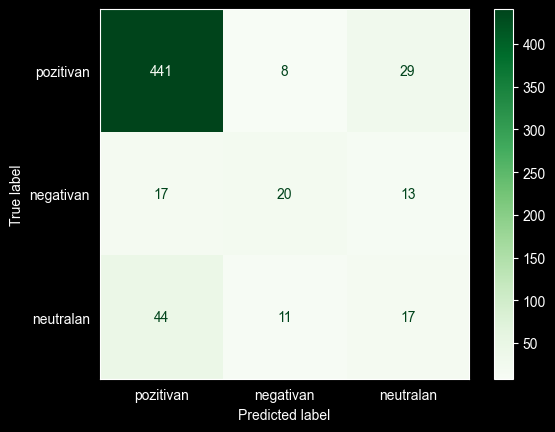

In [31]:
disp = ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, display_labels=y_levels, cmap='Greens')
plt.grid(False)

In [32]:
pred_2 = pipe.predict(X_test)
print(classification_report(y_true=y_test, y_pred=pred_2, target_names=y_levels))

              precision    recall  f1-score   support

   pozitivan       0.88      0.92      0.90       478
   negativan       0.51      0.40      0.45        50
   neutralan       0.29      0.24      0.26        72

    accuracy                           0.80       600
   macro avg       0.56      0.52      0.54       600
weighted avg       0.78      0.80      0.79       600



In [33]:
print(balanced_accuracy_score(y_true=y_test, y_pred=pred_2))

0.5195684177901752


### POREDJENJE KREIRANIH MODELA

In [34]:
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [35]:
models = {
    'TF_SVM': pred_1,
    'TF-SVM-FT': pred_2
}

results_list = list()

for model_name, pred in models.items():
    results_list.append(get_model_metrics(y_true=y_test, y_pred=pred, model_name=model_name))

results_df = pd.DataFrame(results_list)
results_df.set_index('Model', inplace=True)
results_df = results_df.apply(lambda x: round(x,4))

print("Poredjenje uspesnosti modela:")
print(results_df)

Poredjenje uspesnosti modela:
           Macro Precision  Macro Recall  Macro F1-Score  Weighted Precision  \
Model                                                                          
TF_SVM              0.5010        0.5108          0.5056              0.7643   
TF-SVM-FT           0.5598        0.5196          0.5363              0.7772   

           Weighted Recall  Weighted F1-Score  Balanced Accuracy  
Model                                                             
TF_SVM              0.7567             0.7604             0.5108  
TF-SVM-FT           0.7967             0.7856             0.5196  


Model sa optimizovanim vrednostima hiperparametara nije pokazao znacajno bolje rezultate ni po jednoj od globalnih metrika (tj. uproscenih metrika svih klasa).